In [1]:

# ============================================================
# Cell 2: Imports and hardware verification
# ============================================================

import gc
import json
import random
import re
import shutil
import time

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import peft

from tqdm.auto import tqdm
from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)

from peft import PeftModel, PeftConfig
from gptqmodel import GPTQModel, QuantizeConfig

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), (
    "CUDA GPU not found. Enable GPU in Google Colab."
)

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
)

print("GPU:", GPU_NAME)
print("GPU memory:", round(GPU_MEMORY_GB, 2), "GB")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)

assert GPU_MEMORY_GB >= 35, (
    "This notebook is configured for an A100-class "
    "40 GB GPU. Use a larger runtime or a memory-"
    "optimized quantization configuration."
)



INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.10.0
Transformers : 5.22.2
Torch        : 2.14.1+cu130
Triton       : 3.8.0
GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB
PyTorch: 2.14.1+cu130
Transformers: 5.2

In [2]:

# ============================================================
# Cell 3: Project paths and input verification
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/clinical-qa-finetuning-v2"
)

MODEL_ID = "Qwen/Qwen3-4B"

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"

ADAPTER_DIR = (
    MODEL_DIR / "qwen3-medqa-pubmedqa-full-adapter"
)

EVAL_DIR = PROJECT_DIR / "results" / "evaluation"

TRAIN_FILE = DATA_DIR / "combined_train_sft.jsonl"

PREDICTIONS_FILE = (
    EVAL_DIR / "paired_model_predictions.csv"
)

SELECTION_FILE = (
    EVAL_DIR / "evaluation_selection.json"
)

# Work locally during merge and calibration.
WORK_DIR = Path("/content/clinical_qa_gptq")

MERGED_DIR = WORK_DIR / "qwen3-clinical-merged-bf16"
GPTQ_LOCAL_DIR = WORK_DIR / "qwen3-clinical-gptq-int4"

# Persistent Drive destinations.
GPTQ_DRIVE_DIR = (
    MODEL_DIR / "qwen3-clinical-gptq-int4"
)

REPORT_DIR = (
    PROJECT_DIR / "results" / "quantization"
)

WORK_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    ADAPTER_DIR / "adapter_config.json",
    ADAPTER_DIR / "adapter_model.safetensors",
    TRAIN_FILE,
    PREDICTIONS_FILE,
    SELECTION_FILE,
]

for path in required_files:
    assert path.is_file(), f"Required artifact missing: {path}"

adapter_cfg = PeftConfig.from_pretrained(
    str(ADAPTER_DIR)
)

assert adapter_cfg.base_model_name_or_path == MODEL_ID

# Never overwrite an existing merged or GPTQ output.
for path in [MERGED_DIR, GPTQ_LOCAL_DIR, GPTQ_DRIVE_DIR]:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}\n"
            "Inspect the existing artifact before rerunning."
        )

print("Project files verified.")
print("Adapter:", ADAPTER_DIR)
print("Training data:", TRAIN_FILE)
print("Notebook 03 results:", EVAL_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project files verified.
Adapter: /content/drive/MyDrive/clinical-qa-finetuning-v2/models/qwen3-medqa-pubmedqa-full-adapter
Training data: /content/drive/MyDrive/clinical-qa-finetuning-v2/data/combined_train_sft.jsonl
Notebook 03 results: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/evaluation


In [3]:

# ============================================================
# Cell 4: Load the original model in BF16
# ============================================================

assert torch.cuda.is_bf16_supported(), (
    "BF16 is unavailable on the selected GPU."
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.bfloat16,
    device_map={"": 0},
    low_cpu_mem_usage=True,
)

base_model.eval()

load_seconds = time.perf_counter() - start_time

print("Model:", MODEL_ID)
print("Dtype:", next(base_model.parameters()).dtype)
print("Loading time:", round(load_seconds, 2), "seconds")
print(
    "Peak allocated GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Model: Qwen/Qwen3-4B
Dtype: torch.bfloat16
Loading time: 3.29 seconds
Peak allocated GPU memory: 7.49 GB


In [4]:

# ============================================================
# Cell 5: Merge the trained LoRA adapter
# ============================================================

def inspect_adapter(configuration):
    """
    Display the saved adapter's LoRA configuration.

    Parameters
    ----------
    configuration : PeftConfig
        Adapter configuration loaded from Notebook 02.

    Returns
    -------
    None
        Prints the relevant LoRA settings.
    """
    print("LoRA rank:", configuration.r)
    print("LoRA alpha:", configuration.lora_alpha)
    print("Target modules:", configuration.target_modules)


inspect_adapter(adapter_cfg)

assert adapter_cfg.r == 16
assert adapter_cfg.lora_alpha == 32

peft_model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_DIR),
    is_trainable=False,
)

peft_model.eval()

print("Adapter loaded. Merging into BF16 weights...")

merge_start = time.perf_counter()

# Convert the adapter-enhanced model into a standalone model.
merged_model = peft_model.merge_and_unload(
    safe_merge=True
)

merged_model.eval()

merge_seconds = time.perf_counter() - merge_start

print("Merge complete.")
print("Merge time:", round(merge_seconds, 2), "seconds")
print("Merged model type:", type(merged_model).__name__)


LoRA rank: 16
LoRA alpha: 32
Target modules: {'down_proj', 'v_proj', 'k_proj', 'up_proj', 'gate_proj', 'q_proj', 'o_proj'}
Adapter loaded. Merging into BF16 weights...
Merge complete.
Merge time: 0.59 seconds
Merged model type: Qwen3ForCausalLM


In [6]:

# ============================================================
# Cell 6: Save standalone merged model
# ============================================================

MERGED_DIR.mkdir(parents=True, exist_ok=False)

# Store weights in safetensors format.
merged_model.save_pretrained(
    str(MERGED_DIR),
    safe_serialization=True,
    max_shard_size="4GB",
)

# Preserve the tokenizer and chat template.
tokenizer.save_pretrained(str(MERGED_DIR))


def directory_size_gb(directory):
    """
    Measure the on-disk size of a model directory.

    Parameters
    ----------
    directory : Path
        Directory containing model artifacts.

    Returns
    -------
    float
        Total file size in GiB.
    """
    total_bytes = sum(
        path.stat().st_size
        for path in Path(directory).rglob("*")
        if path.is_file()
    )

    return total_bytes / 1024**3


merged_size_gb = directory_size_gb(MERGED_DIR)

print("Merged model saved:", MERGED_DIR)
print("Merged disk size:", round(merged_size_gb, 3), "GiB")
print(
    "Saved model weight files:",
    len(list(MERGED_DIR.glob("*.safetensors")))
)

assert (MERGED_DIR / "config.json").exists()
assert list(MERGED_DIR.glob("*.safetensors"))


Writing model shards:   0%|          | 0/3 [00:00<?, ?it/s]

Merged model saved: /content/clinical_qa_gptq/qwen3-clinical-merged-bf16
Merged disk size: 7.503 GiB
Saved model weight files: 3


In [7]:

# ============================================================
# Cell 7: Free GPU memory before GPTQ calibration
# ============================================================

del merged_model
del peft_model
del base_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


def gpu_memory_stats():
    """
    Print PyTorch GPU memory usage.

    Returns
    -------
    None
        Displays allocated and reserved CUDA memory.
    """
    allocated = (
        torch.cuda.memory_allocated() / 1024**3
    )
    reserved = (
        torch.cuda.memory_reserved() / 1024**3
    )

    print(f"Allocated GPU memory: {allocated:.3f} GiB")
    print(f"Reserved GPU memory: {reserved:.3f} GiB")


gpu_memory_stats()


Allocated GPU memory: 0.008 GiB
Reserved GPU memory: 0.020 GiB


In [8]:

# ============================================================
# Cell 8: Load and normalize calibration source data
# ============================================================

train_data = load_dataset(
    "json",
    data_files=str(TRAIN_FILE),
    split="train",
)

print("Available columns:", train_data.column_names)
print("Training records:", len(train_data))


def calibration_text_from_record(record):
    """
    Convert a training example into GPTQ calibration text.

    Parameters
    ----------
    record : dict
        Normalized training example.

    Returns
    -------
    str
        Text representative of clinical QA inference.

    Raises
    ------
    ValueError
        If the record's format is unsupported.
    """
    # Preferred format: conversational SFT examples.
    messages = record.get("messages")

    if isinstance(messages, list) and messages:
        valid_messages = [
            message
            for message in messages
            if isinstance(message, dict)
            and message.get("role") in {
                "system", "user", "assistant"
            }
            and isinstance(message.get("content"), str)
        ]

        if valid_messages:
            return tokenizer.apply_chat_template(
                valid_messages,
                tokenize=False,
                add_generation_prompt=False,
            )

    # Alternative format: serialized SFT text.
    text_value = record.get("text")

    if isinstance(text_value, str) and text_value.strip():
        return text_value

    # Alternative format: prompt + response/completion.
    prompt = record.get("prompt")
    response = record.get(
        "completion",
        record.get("response"),
    )

    if isinstance(prompt, str) and prompt.strip():
        if isinstance(response, str):
            return prompt + "\n" + response

        return prompt

    raise ValueError(
        "Unsupported training-record schema. "
        f"Available columns: {list(record.keys())}"
    )


# Confirm compatibility before building calibration samples.
sample_text = calibration_text_from_record(train_data[0])

assert isinstance(sample_text, str)
assert sample_text.strip()

print("\nExample calibration text:")
print(sample_text[:600])


Generating train split: 0 examples [00:00, ? examples/s]

Available columns: ['id', 'task', 'messages']
Training records: 12000

Example calibration text:
<|im_start|>system
You are answering educational medical multiple-choice questions. Select the single best answer. Begin with A, B, C, or D.<|im_end|>
<|im_start|>user
Clinical question:
An investigator is studying the structure of the amino-terminal of the Huntingtin protein using x-ray crystallography. The terminal region is determined to have an α-helix conformation. Which of the following forces is most likely responsible for maintaining this conformation?

Answer choices:
A. Hydrophobic interactions
B. Disulfide bonds
C. Peptide bonds
D. Hydrogen bonds

Return only the answer letter.<|im_


In [9]:

# ============================================================
# Cell 9: Build a reproducible GPTQ calibration dataset
# ============================================================

CALIBRATION_SAMPLES = 256
CALIBRATION_MAX_LENGTH = 512
CALIBRATION_BATCH_SIZE = 1

assert len(train_data) >= CALIBRATION_SAMPLES

rng = random.Random(SEED)

selected_indices = rng.sample(
    range(len(train_data)),
    CALIBRATION_SAMPLES,
)

calibration_dataset = []

for index in tqdm(
    selected_indices,
    desc="Preparing calibration samples",
):
    record = train_data[index]
    text = calibration_text_from_record(record)

    # Store a tokenized representation to enforce the
    # calibration sequence-length budget.
    encoded = tokenizer(
        text,
        truncation=True,
        max_length=CALIBRATION_MAX_LENGTH,
        return_tensors="pt",
    )

    calibration_dataset.append(encoded)

assert len(calibration_dataset) == CALIBRATION_SAMPLES

calibration_manifest = {
    "source": str(TRAIN_FILE),
    "seed": SEED,
    "sample_count": CALIBRATION_SAMPLES,
    "max_length": CALIBRATION_MAX_LENGTH,
    "selected_training_indices": selected_indices,
}

with open(
    REPORT_DIR / "gptq_calibration_manifest.json",
    "w",
) as file:
    json.dump(calibration_manifest, file, indent=2)

print("Calibration samples:", len(calibration_dataset))
print("Maximum calibration tokens:", CALIBRATION_MAX_LENGTH)
print("Calibration manifest saved.")


Preparing calibration samples:   0%|          | 0/256 [00:00<?, ?it/s]

Calibration samples: 256
Maximum calibration tokens: 512
Calibration manifest saved.


In [10]:

# ============================================================
# Cell 10: GPTQ 4-bit quantization configuration
# ============================================================

GPTQ_BITS = 4
GPTQ_GROUP_SIZE = 128

quantize_config = QuantizeConfig(
    bits=GPTQ_BITS,
    group_size=GPTQ_GROUP_SIZE,
)

print("Quantization method: GPTQ")
print("Weight bits:", GPTQ_BITS)
print("Group size:", GPTQ_GROUP_SIZE)
print("Calibration samples:", CALIBRATION_SAMPLES)
print("Calibration batch size:", CALIBRATION_BATCH_SIZE)


INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_bibznmx_`
Quantization method: GPTQ
Weight bits: 4
Group size: 128
Calibration samples: 256
Calibration batch size: 1


In [11]:

# ============================================================
# Cell 11: Initialize the GPTQModel quantization engine
# ============================================================

print("Loading merged model for GPTQ quantization...")

load_start = time.perf_counter()

gptq_model = GPTQModel.load(
    str(MERGED_DIR),
    quantize_config=quantize_config,
    device="cuda:0",
    dtype=torch.bfloat16,
)

gptq_load_seconds = time.perf_counter() - load_start

print("GPTQ model initialized.")
print(
    "Load time:",
    round(gptq_load_seconds, 2),
    "seconds"
)

gpu_memory_stats()


Loading merged model for GPTQ quantization...
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/content/clinical_qa_gptq/qwen3-clinical-merged-bf16`


LazyTurtle: loading this checkpoint for quantization, but its shards are not layer-wise: 2 of 3 safetensors files hold multiple model layers (e.g. `model-00002-of-00003.safetensors` holds 21). The same shard is opened and re-read once per layer it holds, adding avoidable I/O during quantization; re-shard so each layer has its own file.


INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}

INFO  Kernel: loaded -> `[]`                                                    
GPTQ model initialized.
Load time: 0.76 seconds
Allocated GPU memory: 0.017 GiB
Reserved GPU memory: 0.021 GiB


In [13]:

# ============================================================
# Fix: Convert BatchEncoding to GPTQ-compatible dictionaries
# ============================================================

def prepare_gptq_calibration(calibration_samples):
    """
    Convert Hugging Face BatchEncoding objects into plain
    Python dictionaries accepted by GPTQModel.

    Parameters
    ----------
    calibration_samples : list
        Tokenized calibration examples from Cell 9.

    Returns
    -------
    list[dict]
        GPTQ-compatible calibration examples containing
        input_ids and attention_mask as integer lists.
    """
    prepared_samples = []

    for sample in calibration_samples:
        # Convert the token IDs to a flat Python integer list.
        input_ids = sample["input_ids"].squeeze(0).tolist()

        attention_mask = (
            sample["attention_mask"].squeeze(0).tolist()
        )

        prepared_samples.append({
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        })

    return prepared_samples


gptq_calibration_dataset = prepare_gptq_calibration(
    calibration_dataset
)

# Confirm that the calibration dataset is valid.
assert len(gptq_calibration_dataset) == 256
assert isinstance(gptq_calibration_dataset[0], dict)
assert isinstance(gptq_calibration_dataset[0]["input_ids"], list)
assert isinstance(gptq_calibration_dataset[0]["input_ids"][0], int)

print("Calibration dataset converted successfully.")
print("Total samples:", len(gptq_calibration_dataset))
print(
    "First sample token count:",
    len(gptq_calibration_dataset[0]["input_ids"])
)
print("Sample keys:", gptq_calibration_dataset[0].keys())


Calibration dataset converted successfully.
Total samples: 256
First sample token count: 178
Sample keys: dict_keys(['input_ids', 'attention_mask'])


In [14]:

# ============================================================
# Cell 12: Run GPTQ post-training quantization
# ============================================================

print("Starting GPTQ INT4 quantization...")
print("Calibration samples:", len(calibration_dataset))
print("Batch size:", CALIBRATION_BATCH_SIZE)

torch.cuda.reset_peak_memory_stats()

quantization_start = time.perf_counter()

# GPTQModel quantizes the prepared model in place.
# The original adapter and merged checkpoint remain unchanged.
quantization_logs = gptq_model.quantize(
    gptq_calibration_dataset,
    batch_size=CALIBRATION_BATCH_SIZE,
)

quantization_seconds = (
    time.perf_counter() - quantization_start
)

quantization_peak_gb = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\nGPTQ quantization completed.")
print(
    "Quantization time:",
    round(quantization_seconds / 60, 2),
    "minutes"
)
print(
    "Peak allocated GPU memory:",
    round(quantization_peak_gb, 2),
    "GiB"
)


Starting GPTQ INT4 quantization...
Calibration samples: 256
Batch size: 1
INFO  Packing Kernel: selected: `TorchLinear`                                   
INFO  Packing Kernel: selected: `TorchLinear`                                   
INFO  Calibration: Sort in descending order by length                           
INFO  Calibration: Total padded tokens: 0                                       
INFO  Calibration: Total non-padded tokens: 74457                               
INFO  Calibration: Total tokens: 74457                                          
INFO  Disk subsystem write throughput detected at 276.2 MB/s.                   
INFO  ModuleLooper: capturing layer inputs from 256 calibration batches         
INFO  Offloading base modules to disk...                                        
INFO  +------------+-------+--------+-------+---------+--------+---------+      
INFO  | region     | count | last_s | avg_s | total_s | pct    | source  |      
INFO  +------------+-------+-------

In [15]:

# ============================================================
# Cell 13: Export standalone GPTQ INT4 checkpoint
# ============================================================

GPTQ_LOCAL_DIR.mkdir(parents=True, exist_ok=False)

# Save the packed GPTQ weights and quantization metadata.
gptq_model.save(str(GPTQ_LOCAL_DIR))

# Preserve Qwen3 tokenizer and chat template.
tokenizer.save_pretrained(str(GPTQ_LOCAL_DIR))

gptq_size_gb = directory_size_gb(GPTQ_LOCAL_DIR)

print("Quantized model saved:", GPTQ_LOCAL_DIR)
print("BF16 model size:", round(merged_size_gb, 3), "GiB")
print("GPTQ model size:", round(gptq_size_gb, 3), "GiB")

size_reduction_pct = (
    (1 - gptq_size_gb / merged_size_gb) * 100
)

print(
    "Checkpoint size reduction:",
    round(size_reduction_pct, 2),
    "%"
)

assert (GPTQ_LOCAL_DIR / "config.json").is_file()
assert list(GPTQ_LOCAL_DIR.glob("*.safetensors"))


Writing model shards: 0it [00:00, ?it/s]

INFO  Saved Quantize Config: 
{
  "bits": 4,
  "group_size": 128,
  "desc_act": false,
  "lm_head": false,
  "method": "gptq",
  "quant_method": "gptq",
  "format": "gptq",
  "checkpoint_format": "gptq",
  "pack_dtype": "int32",
  "meta": {
    "quantizer": [
      "gptqmodel:7.10.0"
    ],
    "uri": "https://github.com/modelcloud/gptqmodel",
    "damp_percent": 0.05,
    "damp_auto_increment": 0.01,
    "static_groups": false,
    "true_sequential": true,
    "mse": 0.0,
    "gptaq": null,
    "foem": null,
    "act_group_aware": true,
    "fallback": {
      "strategy": "rtn",
      "threshold": "0.5%",
      "smooth": null
    },
    "offload_to_disk": true,
    "telemetry": {
      "device": false
    },
    "offload_to_disk_path": "/tmp/gptqmodel_bibznmx_",
    "pack_impl": "auto",
    "gc_mode": "interval",
    "wait_for_submodule_finalizers": false,
    "auto_forward_data_parallel": true,
    "dense_vram_strategy": "exclusive",
    "dense_vram_strategy_devices": null,
    "moe_

In [16]:

# ============================================================
# Cell 14: Back up GPTQ checkpoint to Google Drive
# ============================================================

def verify_directory_copy(source_dir, destination_dir):
    """
    Verify the file inventory and sizes of a directory copy.

    Parameters
    ----------
    source_dir : Path
        Source model directory.
    destination_dir : Path
        Destination model directory.

    Returns
    -------
    bool
        True if all copied files match in name and size.
    """
    source_files = {
        str(p.relative_to(source_dir)): p.stat().st_size
        for p in source_dir.rglob("*")
        if p.is_file()
    }

    destination_files = {
        str(p.relative_to(destination_dir)): p.stat().st_size
        for p in destination_dir.rglob("*")
        if p.is_file()
    }

    return source_files == destination_files


assert not GPTQ_DRIVE_DIR.exists(), (
    f"Destination already exists: {GPTQ_DRIVE_DIR}"
)

shutil.copytree(
    GPTQ_LOCAL_DIR,
    GPTQ_DRIVE_DIR,
)

assert verify_directory_copy(
    GPTQ_LOCAL_DIR,
    GPTQ_DRIVE_DIR,
), "GPTQ checkpoint copy verification failed."

print("GPTQ model backed up to:", GPTQ_DRIVE_DIR)
print("File inventory and sizes verified.")


GPTQ model backed up to: /content/drive/MyDrive/clinical-qa-finetuning-v2/models/qwen3-clinical-gptq-int4
File inventory and sizes verified.


In [17]:

# ============================================================
# Cell 15: Reload the saved GPTQ checkpoint
# ============================================================

# Release calibration and quantization objects.
del gptq_model
del calibration_dataset
del quantization_logs

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("Reloading saved GPTQ model...")

reload_start = time.perf_counter()

quantized_model = GPTQModel.load(
    str(GPTQ_LOCAL_DIR),
    device="cuda:0",
    dtype=torch.bfloat16,
)

reload_seconds = time.perf_counter() - reload_start

print("GPTQ model reloaded.")
print("Reload time:", round(reload_seconds, 2), "seconds")

gpu_memory_stats()


Reloading saved GPTQ model...
from_quantized: adapter: None
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  The layer model.embed_tokens is not quantized.                            
INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  ExLlamaV2 GPTQ: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/exllamav2/ff9cf9920c55c915`.
INFO  ExLlamaV2 GPTQ: torch.ops JIT extension ready in 51s (estimated ~35s, +17s).
INFO  Kernel: Auto-selection: adding candidate `ExllamaV2Linear`                
INFO  Kernel: Auto-selection: adding candidate `TritonV2Linear`                 
INFO  Kernel: Auto-selection: adding candidate `TorchLinear`                    
INFO  Kernel: candidates -> `[MarlinLinear, ExllamaV2Linear, TritonV2Linear, TorchLinear]`
INFO  Kernel: per-module selections -> `[MarlinLinear=252]`                     
INFO  Kernel: selected -> `MarlinLinear`.          

INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       
INFO  Marlin bf16: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/marlin_bf16/d9474aeb231fb261`.
INFO  Marlin bf16: torch.ops JIT extension ready in 134s (estimated ~121s, +13s).
INFO  gc.collect() reclaimed 670 objects in 0.342s                              
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_

In [18]:

# ============================================================
# Cell 16: Smoke-test GPTQ inference
# ============================================================

MEDQA_SYSTEM = (
    "You are answering educational medical "
    "multiple-choice questions. Select the "
    "single best answer. Begin with A, B, C, or D."
)

PUBMEDQA_SYSTEM = (
    "You answer biomedical research questions "
    "using the provided abstract evidence. "
    "Begin your answer with yes, no, or maybe."
)


def build_evaluation_prompt(example):
    """
    Construct the same Qwen3 prompt used in Notebook 03.

    Parameters
    ----------
    example : dict
        Normalized validation example.

    Returns
    -------
    str
        Chat-formatted prompt with an open assistant turn.
    """
    task = example["task"]

    if task == "medqa":
        system_prompt = MEDQA_SYSTEM
    elif task == "pubmedqa":
        system_prompt = PUBMEDQA_SYSTEM
    else:
        raise ValueError(f"Unknown task: {task}")

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": example["prompt"]},
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


def generate_gptq_response(prompt, max_new_tokens=24):
    """
    Generate a deterministic answer using the GPTQ model.

    Parameters
    ----------
    prompt : str
        Fully formatted Qwen3 chat prompt.
    max_new_tokens : int
        Maximum number of response tokens.

    Returns
    -------
    str
        Decoded newly generated tokens only.
    """
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    )

    # GPTQModel's generate wrapper accepts tokenized inputs.
    with torch.inference_mode():
        output = quantized_model.generate(
            inputs=inputs["input_ids"].to("cuda:0"),
            attention_mask=inputs["attention_mask"].to("cuda:0"),
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    # The output includes prompt tokens, so remove them.
    prompt_length = inputs["input_ids"].shape[-1]

    generated_tokens = output[0][prompt_length:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()


example = {
    "task": "medqa",
    "prompt": (
        "Which vitamin deficiency causes scurvy?\n"
        "A. Vitamin A\n"
        "B. Vitamin B12\n"
        "C. Vitamin C\n"
        "D. Vitamin D"
    ),
}

prompt = build_evaluation_prompt(example)

response = generate_gptq_response(prompt)

print("GPTQ response:", repr(response))


GPTQ response: 'C. Vitamin C'


In [19]:

# ============================================================
# Cell 17: Restore Notebook 03's paired evaluation set
# ============================================================

MEDQA_VAL_FILE = DATA_DIR / "medqa_validation.jsonl"
PUBMEDQA_VAL_FILE = DATA_DIR / "pubmedqa_validation.jsonl"

assert MEDQA_VAL_FILE.is_file()
assert PUBMEDQA_VAL_FILE.is_file()

previous_results = pd.read_csv(
    PREDICTIONS_FILE,
    keep_default_na=False,
)

with open(SELECTION_FILE, "r") as file:
    selection_manifest = json.load(file)

medqa_val = load_dataset(
    "json",
    data_files=str(MEDQA_VAL_FILE),
    split="train",
)

pubmedqa_val = load_dataset(
    "json",
    data_files=str(PUBMEDQA_VAL_FILE),
    split="train",
)


def build_task_index(dataset, task):
    """
    Index validation examples by their original IDs.

    Parameters
    ----------
    dataset : datasets.Dataset
        One normalized validation split.
    task : str
        Dataset task identifier.

    Returns
    -------
    dict
        Mapping from question ID to example.
    """
    index = {}

    for row in dataset:
        item = dict(row)

        if item["task"] != task:
            raise ValueError("Unexpected task in validation data.")

        key = str(item["id"])

        if key in index:
            raise ValueError(f"Duplicate evaluation ID: {key}")

        index[key] = item

    return index


medqa_index = build_task_index(medqa_val, "medqa")
pubmedqa_index = build_task_index(pubmedqa_val, "pubmedqa")

evaluation_data = []

for question_id in selection_manifest["medqa_ids"]:
    evaluation_data.append(medqa_index[str(question_id)])

for question_id in selection_manifest["pubmedqa_ids"]:
    evaluation_data.append(pubmedqa_index[str(question_id)])

# Ensure our reference table contains exactly these questions.
expected_keys = {
    (row["task"], str(row["id"]))
    for row in evaluation_data
}

reference_keys = {
    (row["task"], str(row["id"]))
    for _, row in previous_results.iterrows()
}

assert expected_keys == reference_keys, (
    "Notebook 03 predictions and evaluation selection differ."
)

assert len(evaluation_data) == len(previous_results), (
    "Evaluation question count mismatch."
)

print("Matched evaluation questions:", len(evaluation_data))
print("MedQA:", len(selection_manifest["medqa_ids"]))
print("PubMedQA:", len(selection_manifest["pubmedqa_ids"]))


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Matched evaluation questions: 200
MedQA: 100
PubMedQA: 100


In [20]:

# ============================================================
# Cell 18: Parse quantized-model answers
# ============================================================

def extract_answer(response, task):
    """
    Extract a normalized clinical QA answer label.

    Parameters
    ----------
    response : str
        Decoded model response.
    task : str
        Either 'medqa' or 'pubmedqa'.

    Returns
    -------
    str or None
        Parsed answer, or None for an invalid response.
    """
    if not isinstance(response, str):
        return None

    response = re.sub(
        r"<think>.*?</think>",
        "",
        response,
        flags=re.DOTALL | re.IGNORECASE,
    ).strip()

    if "<think>" in response.lower():
        return None

    if task == "medqa":
        patterns = [
            r"^\s*\(?([ABCD])\)?(?:[.):]|\s|$)",
            r"^\s*(?:final\s+answer|correct\s+answer|answer)"
            r"\s*(?:is|:|-)?\s*\(?([ABCD])\)?\b",
        ]

        for pattern in patterns:
            match = re.search(
                pattern,
                response,
                re.IGNORECASE,
            )

            if match:
                return match.group(1).upper()

    elif task == "pubmedqa":
        match = re.match(
            r"^\s*(?:answer\s*:\s*)?(yes|no|maybe)\b",
            response,
            flags=re.IGNORECASE,
        )

        if match:
            return match.group(1).lower()

    else:
        raise ValueError(f"Unknown task: {task}")

    return None


assert extract_answer("C. Vitamin C", "medqa") == "C"
assert extract_answer("Answer: B", "medqa") == "B"
assert extract_answer("yes", "pubmedqa") == "yes"
assert extract_answer("maybe", "pubmedqa") == "maybe"
assert extract_answer("uncertain", "pubmedqa") is None

print("Answer-parser checks passed.")


Answer-parser checks passed.


In [21]:

# ============================================================
# Cell 19: Evaluate GPTQ on identical validation questions
# ============================================================

MAX_CONTEXT = 1024
MAX_NEW_TOKENS = 24

GPTQ_PREDICTIONS_FILE = (
    REPORT_DIR / "gptq_validation_predictions.csv"
)


def evaluate_gptq(examples, save_path, save_every=20):
    """
    Evaluate the GPTQ checkpoint on fixed validation inputs.

    Parameters
    ----------
    examples : list[dict]
        Notebook 03 validation questions.
    save_path : Path
        Destination CSV file.
    save_every : int
        Number of predictions between incremental saves.

    Returns
    -------
    pandas.DataFrame
        Model predictions and correctness indicators.
    """
    records = []

    for example in tqdm(examples, desc="GPTQ evaluation"):
        prompt = build_evaluation_prompt(example)

        input_length = len(
            tokenizer(
                prompt,
                add_special_tokens=False,
            )["input_ids"]
        )

        if input_length + MAX_NEW_TOKENS > MAX_CONTEXT:
            raise ValueError(
                f"Context budget exceeded for {example['id']}"
            )

        response = generate_gptq_response(
            prompt,
            max_new_tokens=MAX_NEW_TOKENS,
        )

        prediction = extract_answer(
            response,
            example["task"],
        )

        records.append({
            "id": str(example["id"]),
            "task": example["task"],
            "expected": example["answer"],
            "gptq_prediction": prediction,
            "gptq_raw": response,
            "gptq_correct": (
                prediction == example["answer"]
            ),
            "gptq_valid": prediction is not None,
        })

        if len(records) % save_every == 0:
            pd.DataFrame(records).to_csv(
                save_path,
                index=False,
            )

    results = pd.DataFrame(records)

    results.to_csv(save_path, index=False)

    return results


gptq_results = evaluate_gptq(
    evaluation_data,
    GPTQ_PREDICTIONS_FILE,
)

print("Evaluated questions:", len(gptq_results))
print("Predictions saved:", GPTQ_PREDICTIONS_FILE)


GPTQ evaluation:   0%|          | 0/200 [00:00<?, ?it/s]

Evaluated questions: 200
Predictions saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/quantization/gptq_validation_predictions.csv


In [22]:

# ============================================================
# Cell 20: Quantization accuracy-retention analysis
# ============================================================

def normalize_boolean_column(series):
    """
    Normalize CSV boolean values to Python booleans.

    Parameters
    ----------
    series : pandas.Series
        Values containing True/False or their string forms.

    Returns
    -------
    pandas.Series
        Boolean values suitable for accuracy calculations.
    """
    normalized = series.astype(str).str.lower()

    assert normalized.isin(["true", "false"]).all(), (
        "Unexpected correctness value in evaluation results."
    )

    return normalized.eq("true")


reference = previous_results[
    ["task", "id", "expected", "finetuned_correct"]
].copy()

reference["id"] = reference["id"].astype(str)

reference["finetuned_correct"] = normalize_boolean_column(
    reference["finetuned_correct"]
)

gptq_comparison = gptq_results.copy()
gptq_comparison["id"] = gptq_comparison["id"].astype(str)

comparison = reference.merge(
    gptq_comparison,
    on=["task", "id"],
    how="inner",
    suffixes=("_reference", "_gptq"),
    validate="one_to_one",
)

assert len(comparison) == len(reference)
assert (
    comparison["expected_reference"]
    == comparison["expected_gptq"]
).all(), "Ground-truth answer mismatch."

comparison_rows = []

for task in ["medqa", "pubmedqa"]:
    task_df = comparison[comparison["task"] == task]

    ft_accuracy = float(
        task_df["finetuned_correct"].mean()
    )

    gptq_accuracy = float(
        task_df["gptq_correct"].mean()
    )

    accuracy_change_pp = (
        gptq_accuracy - ft_accuracy
    ) * 100

    comparison_rows.append({
        "task": task,
        "samples": len(task_df),
        "finetuned_accuracy": ft_accuracy,
        "gptq_accuracy": gptq_accuracy,
        "accuracy_change_pp": accuracy_change_pp,
        "gptq_valid_rate": float(
            task_df["gptq_valid"].mean()
        ),
    })

quant_metrics_df = pd.DataFrame(comparison_rows)

macro_ft = float(
    quant_metrics_df["finetuned_accuracy"].mean()
)

macro_gptq = float(
    quant_metrics_df["gptq_accuracy"].mean()
)

macro_change_pp = (macro_gptq - macro_ft) * 100

print("=" * 60)
print("GPTQ QUANTIZATION ACCURACY RETENTION")
print("=" * 60)

display(quant_metrics_df)

print(f"Fine-tuned macro accuracy: {macro_ft:.2%}")
print(f"GPTQ macro accuracy: {macro_gptq:.2%}")
print(f"Accuracy change: {macro_change_pp:+.2f} pp")

assert abs(macro_ft - 0.75) < 1e-9, (
    "The Notebook 03 reference does not match the "
    "previously reported 75% macro accuracy."
)


GPTQ QUANTIZATION ACCURACY RETENTION


,task,samples,finetuned_accuracy,gptq_accuracy,accuracy_change_pp,gptq_valid_rate
0,medqa,100,0.67,0.62,-5.0,1.0
1,pubmedqa,100,0.83,0.83,0.0,1.0


Fine-tuned macro accuracy: 75.00%
GPTQ macro accuracy: 72.50%
Accuracy change: -2.50 pp


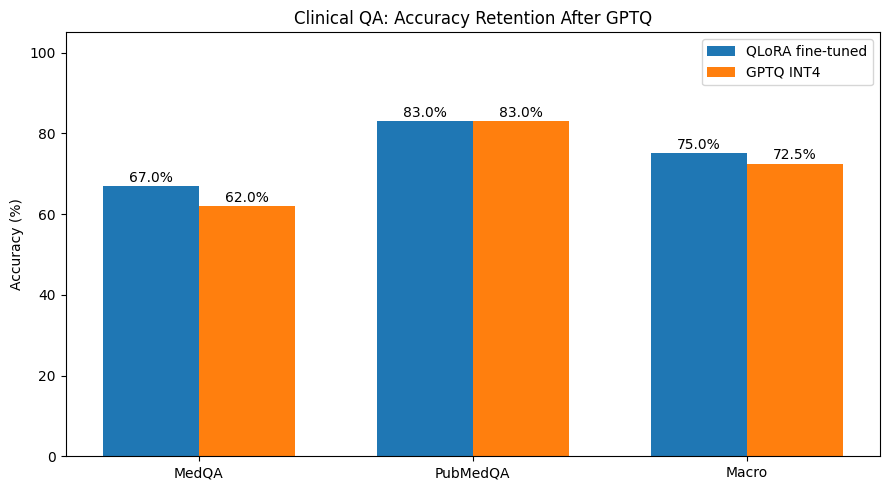

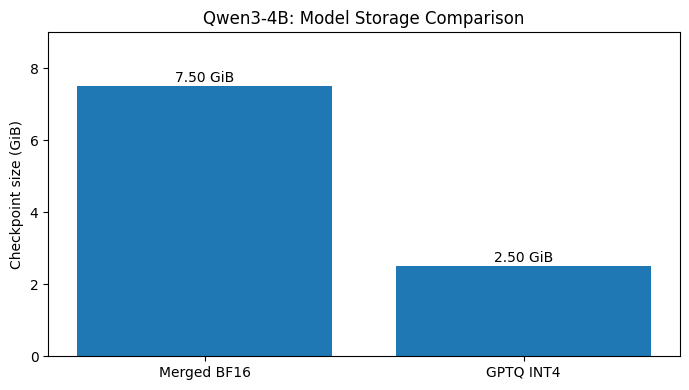

In [23]:

# ============================================================
# Cell 21: Visualize accuracy retention and size reduction
# ============================================================

tasks = ["MedQA", "PubMedQA", "Macro"]

reference_scores = [
    *(
        quant_metrics_df["finetuned_accuracy"]
        .to_numpy() * 100
    ),
    macro_ft * 100,
]

quantized_scores = [
    *(
        quant_metrics_df["gptq_accuracy"]
        .to_numpy() * 100
    ),
    macro_gptq * 100,
]

x = np.arange(len(tasks))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_reference = ax.bar(
    x - width / 2,
    reference_scores,
    width,
    label="QLoRA fine-tuned",
)

bars_quantized = ax.bar(
    x + width / 2,
    quantized_scores,
    width,
    label="GPTQ INT4",
)

ax.set_xticks(x)
ax.set_xticklabels(tasks)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)
ax.set_title("Clinical QA: Accuracy Retention After GPTQ")
ax.legend()

for bars in [bars_reference, bars_quantized]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.1f}%",
            (
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
        )

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "gptq_accuracy_retention.png",
    dpi=150,
)
plt.show()

# Plot model checkpoint sizes separately.
fig, ax = plt.subplots(figsize=(7, 4))

size_bars = ax.bar(
    ["Merged BF16", "GPTQ INT4"],
    [merged_size_gb, gptq_size_gb],
)

ax.set_ylabel("Checkpoint size (GiB)")
ax.set_title("Qwen3-4B: Model Storage Comparison")

for bar in size_bars:
    ax.annotate(
        f"{bar.get_height():.2f} GiB",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
    )

ax.set_ylim(
    0,
    max(merged_size_gb, gptq_size_gb) * 1.2
)

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "gptq_model_size_comparison.png",
    dpi=150,
)
plt.show()


In [24]:

# ============================================================
# Cell 22: GPTQ quantization acceptance gates
# ============================================================

MAX_ACCEPTABLE_DROP_PP = 2.0
MIN_VALID_RATE = 0.95


def check_gptq_gates(metrics, macro_change):
    """
    Evaluate provisional accuracy and answer-validity gates.

    Parameters
    ----------
    metrics : pandas.DataFrame
        Per-task quantization accuracy comparisons.
    macro_change : float
        Macro accuracy change in percentage points.

    Returns
    -------
    dict
        Individual checks and overall decision.
    """
    gates = {
        "macro_accuracy_retained": (
            macro_change >= -MAX_ACCEPTABLE_DROP_PP
        ),
    }

    for _, row in metrics.iterrows():
        task = row["task"]

        gates[f"{task}_accuracy_retained"] = (
            row["accuracy_change_pp"]
            >= -MAX_ACCEPTABLE_DROP_PP
        )

        gates[f"{task}_valid_answers"] = (
            row["gptq_valid_rate"] >= MIN_VALID_RATE
        )

    passed = all(gates.values())

    return {
        "checks": gates,
        "passed": passed,
        "decision": (
            "PROVISIONAL PASS"
            if passed
            else "HOLD - INVESTIGATE REGRESSION"
        ),
    }


gptq_gate_result = check_gptq_gates(
    quant_metrics_df,
    macro_change_pp,
)

print("GPTQ REGRESSION GATES")
print("=" * 50)

for gate, passed in gptq_gate_result["checks"].items():
    print(f"{gate}: {'PASS' if passed else 'FAIL'}")

print("\nDecision:", gptq_gate_result["decision"])


GPTQ REGRESSION GATES
macro_accuracy_retained: FAIL
medqa_accuracy_retained: FAIL
medqa_valid_answers: PASS
pubmedqa_accuracy_retained: PASS
pubmedqa_valid_answers: PASS

Decision: HOLD - INVESTIGATE REGRESSION


In [25]:

# ============================================================
# Diagnostic A: Quantify GPTQ accuracy regression
# ============================================================

def show_quantization_regression(metrics, macro_before, macro_after):
    """
    Display task-level and macro accuracy before and after GPTQ.

    Parameters
    ----------
    metrics : pandas.DataFrame
        Output from Notebook 04, Cell 20.
    macro_before : float
        Fine-tuned reference macro accuracy.
    macro_after : float
        GPTQ model macro accuracy.

    Returns
    -------
    None
        Prints formatted comparisons.
    """
    for _, row in metrics.iterrows():
        print(f"\nTask: {row['task'].upper()}")
        print(f"Fine-tuned: {row['finetuned_accuracy']:.2%}")
        print(f"GPTQ:       {row['gptq_accuracy']:.2%}")
        print(
            f"Change:     {row['accuracy_change_pp']:+.2f} pp"
        )
        print(f"Valid answers: {row['gptq_valid_rate']:.2%}")

    print("\n" + "=" * 50)
    print(f"Reference macro accuracy: {macro_before:.2%}")
    print(f"GPTQ macro accuracy:      {macro_after:.2%}")
    print(
        f"Macro change: {(macro_after - macro_before) * 100:+.2f} pp"
    )


show_quantization_regression(
    quant_metrics_df,
    macro_ft,
    macro_gptq,
)



Task: MEDQA
Fine-tuned: 67.00%
GPTQ:       62.00%
Change:     -5.00 pp
Valid answers: 100.00%

Task: PUBMEDQA
Fine-tuned: 83.00%
GPTQ:       83.00%
Change:     +0.00 pp
Valid answers: 100.00%

Reference macro accuracy: 75.00%
GPTQ macro accuracy:      72.50%
Macro change: -2.50 pp


In [26]:

# ============================================================
# Cell 23: Export the quantization experiment report
# ============================================================

quantization_report = {
    "experiment": "qwen3-clinical-gptq-int4",
    "source_model": MODEL_ID,
    "source_adapter": str(ADAPTER_DIR),
    "quantized_model": str(GPTQ_DRIVE_DIR),
    "method": "GPTQ",
    "weight_bits": GPTQ_BITS,
    "group_size": GPTQ_GROUP_SIZE,
    "calibration_samples": CALIBRATION_SAMPLES,
    "calibration_max_length": CALIBRATION_MAX_LENGTH,
    "calibration_batch_size": CALIBRATION_BATCH_SIZE,
    "gpu": GPU_NAME,
    "merged_bf16_size_gib": merged_size_gb,
    "gptq_size_gib": gptq_size_gb,
    "size_reduction_percent": size_reduction_pct,
    "quantization_minutes": quantization_seconds / 60,
    "quantization_peak_allocated_gpu_gib": (
        quantization_peak_gb
    ),
    "gptq_reload_seconds": reload_seconds,
    "gptq_loaded_allocated_gpu_gib": (
        torch.cuda.memory_allocated() / 1024**3
    ),
    "evaluation_split": "validation",
    "evaluation_samples": len(comparison),
    "finetuned_macro_accuracy": macro_ft,
    "gptq_macro_accuracy": macro_gptq,
    "macro_accuracy_change_pp": macro_change_pp,
    "per_task_results": (
        quant_metrics_df.to_dict(orient="records")
    ),
    "regression_gates": gptq_gate_result,
    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
}

REPORT_FILE = (
    REPORT_DIR / "gptq_quantization_report.json"
)

with open(
    REPORT_FILE,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        quantization_report,
        file,
        indent=4,
    )

quant_metrics_df.to_csv(
    REPORT_DIR / "gptq_accuracy_comparison.csv",
    index=False,
)

comparison.to_csv(
    REPORT_DIR / "gptq_paired_comparison.csv",
    index=False,
)

print("Quantization report saved:", REPORT_FILE)
print("Quantized checkpoint saved:", GPTQ_DRIVE_DIR)
print("Final gate decision:", gptq_gate_result["decision"])


Quantization report saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/quantization/gptq_quantization_report.json
Quantized checkpoint saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/models/qwen3-clinical-gptq-int4
Final gate decision: HOLD - INVESTIGATE REGRESSION
